<a href="https://colab.research.google.com/github/MrCoconut203/main/blob/main/%E3%83%87%E3%83%BC%E3%82%BF%E3%82%B5%E3%82%A4%E3%82%A8%E3%83%B3%E3%82%B9%E8%AA%B2%E9%A1%8C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  新しい条件での熱中症搬送人員予測 (ノットブックの最後にあります)
使用したデータ

    1.最終ワーク_データ手順付き.xlsx
    2.heatstroke003_data_r7.xlsx

    2025年の予測値と実測値の比較は最終ワーク_データ手順付き.xlsxに挿入します(google driveでご覧ください）
    
    学習データ（メインデータ）を含むExcelファイルへのパス。
    2025年の予測値と実測値の比較は最終ワーク_データ手順付き.xlsxに挿入します
    Google Driveの構成が異なる場合は 「1. データ収集と前処理」で、このパスを更新してください。
    FILE_PATH = "/content/drive/MyDrive/最終ワーク_データ手順付き.xlsx"

    2025年の実測データを含むExcelファイルへのパス。
    Google Driveの構成が異なる場合は、このパスを更新してください。
    ACTUAL_DATA_FILE_PATH = "/content/drive/MyDrive/heatstroke003_data_r7.xlsx"

![hello](https://drive.google.com/uc?id=116Vh8KOvm21pDSsAhue1Ggz_211cFuZx)
#1.問題提起

熱中症の現状と課題 ― 日本における年次動向

近年、日本では猛暑日の増加や気温の上昇に伴い、熱中症による救急搬送・入院患者数が著しく増加している。消防庁の統計によると、2024年5月から9月までの期間で、全国で 約97,578人 が熱中症により救急搬送され、これは過去最多の記録となった。また同期間中に 120人 が搬送前に死亡しており、高齢者（65歳以上）が全体の約6割を占めたことが報告されている。

2025年の夏も記録的な高温となっており、同年5月～9月までに 100,143人 が熱中症で搬送され、前年を上回る過去最高数となったことが公表された。このうち約 57,235人 が高齢者であり、中でも東京・大阪・愛知など人口密集地域での発生件数が多い。

こうした状況は、救急医療体制にも大きな負担をもたらしている。救急車の出動は無料であり、消防・救急隊員は高温下で多数の搬送対応を強いられている。また、熱中症警戒アラートが導入されるなど予防体制の強化が進められているが、搬送患者数の増加傾向は続いている。
![hello](https://drive.google.com/uc?id=1jzLyz_mWccgyHakhqQtNHSHwzXEakpC-)

## 熱中症搬送人員数予測モデルの数式

本プロジェクトで構築された Generalized Additive Model (GAM) は、目的変数である熱中症搬送人員数に対して `log(y+1)` の対数変換を適用しています。これにより、予測される値が非負に保たれ、データの歪みが緩和されます。

モデルの予測値 (`Y_pred_log`) は、各特徴量に対する平滑化関数（スプライン関数）の合計として表されます。

**log(熱中症搬送人員 + 1) = intercept + s₁(最低気温) + s₂(最高気温) + s₃(平均湿度) + s₄(最小相対湿度) + s₅(平均蒸気圧) + s₆(month_sin) + s₇(month_cos) + s₈(day_of_week_sin) + s₉(day_of_week_cos)**

ここで：
- `intercept` はモデルの切片（ベースライン値）です。
- `sᵢ(Feature)` は、各特徴量に対して適用される**平滑化関数（スプライン関数）**です。これらの関数により、特徴量と目的変数との間の非線形な関係を柔軟に捉えることができます。
- 各変数は以下の通りです。
  - `最低気温(℃)`: その日の最低気温
  - `最高気温(℃)`: その日の最高気温
  - `平均湿度(％)`: その日の平均湿度
  - `最小相対湿度(％)`: その日の最小相対湿度
  - `平均蒸気圧(hPa)`: その日の平均蒸気圧
  - `month_sin`, `month_cos`: 月の周期性を表す特徴量（季節性）
  - `day_of_week_sin`, `day_of_week_cos`: 曜日の周期性を表す特徴量（週次パターン）

最終的な熱中症搬送人員数（元のスケール）を得るためには、モデルの予測結果に対して逆変換を適用します。

**熱中症搬送人員 = exp(log(熱中症搬送人員 + 1)) - 1**

つまり、

**熱中症搬送人員 = exp(intercept + s₁(最低気温) + s₂(最高気温) + s₃(平均湿度) + s₄(最小相対湿度) + s₅(平均蒸気圧) + s₆(month_sin) + s₇(month_cos) + s₈(day_of_week_sin) + s₉(day_of_week_cos)) - 1**

この数式は、様々な気象条件や時間的要因が熱中症搬送人員数にどのように影響するかを、非線形な関係性を含めて表現しています。

#2.熱中症患者数予測プロジェクト

本プロジェクトは、**熱中症**による患者数を予測することを目的としています。  
熱中症は、特に**気候変動**の影響により、年々深刻化している公衆衛生上の問題です。  
本研究の主な目的は、**信頼性の高い予測モデル**を構築し、医療機関や地域社会が高温時に**迅速かつ適切に対応**できるよう支援することです。

---

## 課題の特徴

- **気象データ:**  
  以下のような気象変数を主な入力データとして使用します。
  - 最低気温  
  - 最高気温  
  - 平均湿度  
  - 最小相対湿度  
  - 平均水蒸気圧  

- **熱中症データ:**  
  熱中症により入院した患者数を**目的変数**として使用します。

- **季節性:**  
  熱中症の発生件数は明確な季節性を持ち、夏季に増加し、他の季節には減少します。  
  そのため、モデルには**季節的変動**や**曜日ごとの傾向**を捉える能力が求められます。

- **非線形性:**  
  気象条件と熱中症患者数の関係は、単純な線形関係ではありません。

---

# アプローチ手法

本プロジェクトでは、予測モデルの構築に **Generalized Additive Models（GAM）** を採用しました。  
GAM は、スプライン関数を用いて説明変数と目的変数の**非線形な関係**を柔軟に表現できる統計手法です。
![hello](https://drive.google.com/uc?id=1RyXQdo8mip4BrQOV_1Wcbdq213TzZkCv)
## 手順

1. **データ収集と前処理:**  
   Excel ファイルから気象データおよび熱中症患者数の履歴データを取得し、  
   欠損値や異常値は**平均値で補完**しました。

2. **特徴エンジニアリング:**
   以下のような新しい特徴量を作成しました。
   - 相互作用特徴量（例: `temp_humidity`, `max_temp_sq`）
   - 周期的時間特徴量（例: `month_sin`, `month_cos`, `day_of_week_sin`, `day_of_week_cos`）  
   これにより、季節性や週次パターンをより正確に捉えます。

3. **目的変数の変換:**  
   データの歪みやゼロ値への対応として、`log(y + 1)` の対数変換を適用しました。

4. **データ分割:**  
   データ漏洩を防ぐため、時系列順に**学習データ**と**検証データ**に分割しました。

5. **GAM モデルの学習:**  
   各特徴量にスプライン関数を適用した `LinearGAM` モデルを構築・学習しました。

6. **モデル評価:**  
   以下の指標を用いてモデル性能を評価しました。
   - MAE  
   - RMSE  
   - 決定係数（R-squared）  

7. **予測と比較:**  
   学習済みモデルを用いて **2025年** の熱中症患者数を予測し、  
   実際に収集されたデータと比較しました。
8. 熱中症危険日の特徴や予測と予防策につながる知見
9. 新しい条件での熱中症搬送人員予測

   
---   
## 使用したデータ
1. 最終ワーク_データ手順付き.xlsx
2. heatstroke003_data_r7.xlsx

     2025年の予測値と実測値の比較は最終ワーク_データ手順付き.xlsxに挿入します(google driveでご覧ください）
     

---
##3.仮説と考察
 **モデル変数と熱中症搬送人員数の関連性**
---
本GAM（Generalized Additive Models）モデルは、過去の気象データと熱中症搬送人員数を用いて、将来の熱中症発生を予測することを目的としています。モデルの分析結果と、熱中症に関する一般的な知見に基づき、各モデル変数と熱中症搬送人員数の関連性について考察します。

---

### 1. 気象変数

熱中症の発生は、気象条件に強く影響されます。

*   **最高気温(℃):**
    *   **仮説:** 最高気温が高いほど、熱中症のリスクは著しく増加します。
    *   **考察:** モデルの統計的評価でも、最高気温は熱中症搬送人員数に対して最も強い非線形な正の関連性を示す主要な予測因子であることが確認されました。特定の閾値を超えると、搬送人員数が急増する傾向が見られます。

*   **平均湿度(％) & 最小相対湿度(％):**
    *   **仮説:** 湿度が高いほど、汗の蒸発が妨げられ、体感温度が上昇するため、熱中症のリスクが高まります。
    *   **考察:** 危険日の分析では、「非常に高い最高気温」に加えて「高めの湿度」が共通して観察されました。これにより、体温調節機能が低下し、熱中症のリスクが著しく高まることが示唆されます。

*   **平均蒸気圧(hPa):**
    *   **仮説:** 蒸気圧は空気中の水蒸気量を示すため、これが高いほど湿度が高く、熱中症リスクに関連すると考えられます。
    *   **考察:** 最高気温や湿度と相関があり、同様に熱中症リスクに寄与する可能性があります。特に、湿度と合わせて体感温度に影響を与えます。

*   **最低気温(℃):**
    *   **仮説:** 夜間の最低気温が高い（熱帯夜など）と、体が冷えず疲労が蓄積しやすくなるため、翌日の熱中症リスクを高める可能性があります。
    *   **考察:** 最高気温ほど直接的な影響は大きくないかもしれませんが、累積的な熱ストレスの要因として重要です。

---

### 2. 時間ベースの特徴量（季節性と曜日ごとの傾向）

熱中症の発生は、時期によって明確なパターンがあります。

*   **`month_sin`, `month_cos` (月周期変数):**
    *   **仮説:** 熱中症は夏季に集中して発生するため、月によってそのリスクが大きく変動します。
    *   **考察:** これらの変数は季節性（特に夏季のピーク）を非常に効果的に捉えており、モデルにおいて熱中症搬送人員数を予測する上で非常に重要な因子であることが示されました。

*   **`day_of_week_sin`, `day_of_week_cos` (曜日周期変数):**
    *   **仮説:** 曜日によって人々の活動パターンが異なるため、熱中症の発生にも曜日ごとの傾向が存在する可能性があります（例：週末のレジャー活動による増加など）。
    *   **考察:** モデルでは季節性ほど強い影響は示されませんでしたが、特定の曜日における活動量の違いや注意喚起の頻度などが搬送人員数に影響を与える可能性があります。

---

### まとめ

熱中症搬送人員数は、**最高気温と湿度**が組み合わさった**熱ストレスの度合い**と、**季節的な変動**に強く関連していることが示唆されます。特に、夏場の高気温と高湿度が予測の主要なドライバーであり、これらの要因を正確にモデル化することが、熱中症予測の精度向上に不可欠です。モデルは、これらの非線形な関係を柔軟に捉えることで、より信頼性の高い予測を実現しています。

## 1. データ収集と前処理






In [ ]:
# Google Driveをマウントします。
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# === ファイルパスの設定 ===

# 学習データ（メインデータ）を含むExcelファイルへのパス。
# 2025年の予測値と実測値の比較は最終ワーク_データ手順付き.xlsxに挿入します
# Google Driveの構成が異なる場合は、このパスを更新してください。
FILE_PATH = "/content/drive/MyDrive/最終ワーク_データ手順付き.xlsx"

# 2025年の実測データを含むExcelファイルへのパス。
# Google Driveの構成が異なる場合は、このパスを更新してください。
ACTUAL_DATA_FILE_PATH = "/content/drive/MyDrive/heatstroke003_data_r7.xlsx"

# 別の場所に保存した場合は、このパスを更新してください。
print("ファイルパスが定義されました。必要に応じて確認・更新してください。")


ファイルパスが定義されました。必要に応じて確認・更新してください。


In [ ]:
# 必要なライブラリをインポートします。
!pip install pygam
# 日本語フォントをインストールします。
!pip install japanize-matplotlib
import pandas as pd
import numpy as np
# Matplotlibを再ロードし、日本語フォントを設定します。
import matplotlib.pyplot as plt
import japanize_matplotlib

# matplotlibのキャッシュをクリア（重要）
# import matplotlib
# matplotlib.font_manager._rebuild()

print("日本語フォントが設定されました。")

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from pygam import LinearGAM, s
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 86.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120257 sha256=c27961658d1033f50358dd09d74cbefe0ef540fd2155f566a21646250a5b82b7
  Stored in directory: /root/.cache/pip/wheels/c1/f7/9b/418f19a7b9340fc16e071e89efc379aca68d40238b258df53d
Successfully built japanize-matplotlib
日本語フォントが設定されました。


In [ ]:
# Excelファイルから学習データをロードします。
# 元のExcelファイル
FILE_PATH = "/content/drive/MyDrive/最終ワーク_データ手順付き.xlsx"  # 名前が異なる場合は変更

# 学習用シート
df_train = pd.read_excel(
    FILE_PATH,
    sheet_name="分析用気象_22_24_学習用"
)

df_train.head()

,年月日 東京都,平均気温(℃),最高気温(℃),最低気温(℃),日照時間(時間),平均蒸気圧(hPa),平均湿度(％),最小相対湿度(％),熱中症搬送人員（計）,熱中症搬送人数 (LOG)
0,2022/5/1,12.7,16.8,10.8,0.0,12.0,83,57,1,NaN
1,2022/5/2,13.3,19.4,9.5,4.1,11.0,74,31,0,NaN
2,2022/5/3,15.2,20.4,9.3,12.3,10.4,63,28,3,NaN
3,2022/5/4,17.9,25.0,10.8,12.4,11.8,60,33,5,NaN
4,2022/5/5,19.8,26.3,13.6,11.8,14.6,65,36,7,NaN


## 2. 特徴エンジニアリング

In [ ]:
# NaN値と0値のデータクレンジングを行います。

# SettingWithCopyWarningを避けるためにコピー
df_train = df_train.copy()

TARGET_COL = "熱中症搬送人員（計）"

FEATURE_COLS = [
    "最低気温(℃)",
    "最高気温(℃)",
    "平均湿度(％)",
    "最小相対湿度(％)",
    "平均蒸気圧(hPa)",
    "日照時間(時間)"
]
#特徴量エンジニアリング <1>
df_train["temp_humidity"] = (
    df_train["最高気温(℃)"] * df_train["平均湿度(％)"])
FEATURE_COLS.append("temp_humidity")

#特徴量エンジニアリング <2>
df_train["max_temp_sq"] = df_train["最高気温(℃)"] ** 2
FEATURE_COLS.append("max_temp_sq")


# クリーニングが必要な列（名前はそのまま）
CLEAN_COLS = FEATURE_COLS + [TARGET_COL]

# <1> 不合理な0値をNaNに置換
# (気象変数と目的変数に適用)
for col in CLEAN_COLS:
    df_train.loc[df_train[col] == 0, col] = np.nan

# <2> 過度に大きな値をNaNに置換 (目的変数のみ)
# 例: 平均 + 3標準偏差 を超える値を外れ値とする
# この閾値はデータの特性に応じて調整できます。
#mean_target = df_train[TARGET_COL].mean()
#std_target = df_train[TARGET_COL].std()
#upper_bound = mean_target + (3 * std_target)

#df_train.loc[df_train[TARGET_COL] > upper_bound, TARGET_COL] = np.nan

#print(f"閾値を超える外れ値がNaNに置換されました。閾値: {upper_bound:.2f}")
# 異常値削除ステープを試した上で精度が低下された為、この部分を無効します
# <3> NaN値を各列の平均値で補完
for col in CLEAN_COLS:
    mean_value = df_train[col].mean()
    df_train[col] = df_train[col].fillna(mean_value)


# <4> 再度確認
print("各列に残っているNaN:")
print(df_train[CLEAN_COLS].isna().sum())

各列に残っているNaN:
最低気温(℃)          0
最高気温(℃)          0
平均湿度(％)          0
最小相対湿度(％)        0
平均蒸気圧(hPa)       0
日照時間(時間)         0
temp_humidity    0
max_temp_sq      0
熱中症搬送人員（計）       0
dtype: int64


## 3. 目的変数の変換

In [ ]:
# 特徴量(X)と目的変数(y)を定義し、目的変数にlog(y+1)変換を適用します。
X = df_train[FEATURE_COLS]
y = df_train[TARGET_COL]

# log(x+1)
y_log = np.log(y + 1)

In [ ]:
# ================================
# 1. 日付列をdatetime型に変換
# ================================
df_train['年月日 東京都'] = pd.to_datetime(df_train['年月日 東京都'])

# ================================
# 2. データを時系列順にソート
#    (データリーケージを防ぐために非常に重要)
# ================================
df_train = df_train.sort_values(by='年月日 東京都').reset_index(drop=True)

# ================================
# 3. 時間ベースの特徴量エンジニアリング
# ================================

# 月 (1–12)
df_train['month'] = df_train['年月日 東京都'].dt.month

# 周期変数 (モデルが季節性を理解するのに役立つ)
df_train['month_sin'] = np.sin(2 * np.pi * df_train['month'] / 12)
df_train['month_cos'] = np.cos(2 * np.pi * df_train['month'] / 12)

# ================================
# 4. 特徴量 (X) と目的変数 (y) を定義
# ================================

FEATURE_COLS = [
    # --- 元の気象変数 ---
    '最低気温(℃)',
    '最高気温(℃)',
    '平均湿度(％)',
    '最小相対湿度(％)',
    '平均蒸気圧(hPa)',

    # --- 時間特徴量 ---
    'month_sin',
    'month_cos'
]

TARGET_COL = '熱中症搬送人員（計）'

X = df_train[FEATURE_COLS]
y = df_train[TARGET_COL]

# ================================
# 5. 目的変数の対数変換
#    (歪度の処理 + 多数の0値の処理)
# ================================
y_log = np.log(y + 1)

# ================================
# 6. 時系列順にデータを分割
#    (シャッフルしない)
# ================================
test_size = 0.2
split_idx = int(len(df_train) * (1 - test_size))

X_train = X.iloc[:split_idx]
X_valid = X.iloc[split_idx:]

y_train = y_log.iloc[:split_idx]
y_valid = y_log.iloc[split_idx:]

# ================================
# 7. データセットのサイズを確認
# ================================
print(f"学習データセットのサイズ: {len(X_train)}")
print(f"検証データセットのサイズ: {len(X_valid)}")

学習データセットのサイズ: 367
検証データセットのサイズ: 92


In [ ]:
# 2025年の評価用データをロードします。
df_2025 = pd.read_excel(
    FILE_PATH,
    sheet_name="分析用気象_25_評価用"
)

df_2025.head()

,年月日 東京都,平均気温(℃),最高気温(℃),最低気温(℃),日照時間(時間),平均蒸気圧(hPa),平均湿度(％),最小相対湿度(％),熱中症搬送人員（予測値LOG)）,熱中症搬送人員（予測値真数),熱中症搬送人員（実測）,残差
0,2025-05-01,18.2,23.8,12.9,10.7,14.5,71,44,1.612038,4,3,-1
1,2025-05-02,16.2,18.7,14.0,0.0,16.7,90,73,3.163613,23,1,-22
2,2025-05-03,18.2,24.6,13.6,12.2,12.3,61,27,1.789652,5,4,-1
3,2025-05-04,18.5,25.9,13.7,8.1,15.4,73,52,1.717411,5,3,-2
4,2025-05-05,17.7,23.9,11.6,9.9,11.7,58,37,1.609833,4,3,-1


## 4. データ分割

In [ ]:
# 1. df_train と df_2025 の両方に 'day_of_week' 列を追加
# 2. df_train と df_2025 の両方に周期的な特徴量 'day_of_week_sin' および 'day_of_week_cos' を作成
# 3. 'day_of_week_sin' と 'day_of_week_cos' を含むように FEATURE_COLS のリストを更新
# 4. X, X_train, X_valid, X_2025, y, y_log, y_train, y_valid の DataFrame を再生成

# --- df_train ---
# df_train の '年月日 東京都' はすでにdatetime型（以前のセルで変換済み）。
df_train['day_of_week'] = df_train['年月日 東京都'].dt.dayofweek

# 曜日の周期変数
df_train['day_of_week_sin'] = np.sin(2 * np.pi * df_train['day_of_week'] / 7)
df_train['day_of_week_cos'] = np.cos(2 * np.pi * df_train['day_of_week'] / 7)

# --- df_2025 ---
# 特徴量を作成する前に、日付列をdatetime型に変換
df_2025['年月日 東京都'] = pd.to_datetime(df_2025['年月日 東京都'])

# 'day_of_week' を追加
df_2025['day_of_week'] = df_2025['年月日 東京都'].dt.dayofweek

# 曜日の周期変数
df_2025['day_of_week_sin'] = np.sin(2 * np.pi * df_2025['day_of_week'] / 7)
df_2025['day_of_week_cos'] = np.cos(2 * np.pi * df_2025['day_of_week'] / 7)

# df_2025 に 'month' と周期変数 'month_sin', 'month_cos' を追加
df_2025['month'] = df_2025['年月日 東京都'].dt.month
df_2025['month_sin'] = np.sin(2 * np.pi * df_2025['month'] / 12)
df_2025['month_cos'] = np.cos(2 * np.pi * df_2025['month'] / 12)

# --- FEATURE_COLS を更新 ---
FEATURE_COLS = [
    '最低気温(℃)',
    '最高気温(℃)',
    '平均湿度(％)',
    '最小相対湿度(％)',
    '平均蒸気圧(hPa)',
    'month_sin',
    'month_cos',
    'day_of_week_sin',
    'day_of_week_cos'
]

TARGET_COL = '熱中症搬送人員（計）'

# --- X, y, y_log を再生成 ---
X = df_train[FEATURE_COLS]
y = df_train[TARGET_COL]
y_log = np.log(y + 1)

# --- 訓練/検証セットを再生成 (時系列順、シャッフルなし) ---
test_size = 0.2
split_idx = int(len(df_train) * (1 - test_size))

X_train = X.iloc[:split_idx]
X_valid = X.iloc[split_idx:]

y_train = y_log.iloc[:split_idx]
y_valid = y_log.iloc[split_idx:]

# --- X_2025 を再生成 ---
X_2025 = df_2025[FEATURE_COLS]

# 更新されたデータセットのサイズを確認
print(f"学習データセットのサイズ (更新後): {len(X_train)}")
print(f"検証データセットのサイズ (更新後): {len(X_valid)}")
print(f"2025年予測用データセットのサイズ (更新後): {len(X_2025)}")
print(f"更新されたFEATURE_COLS: {FEATURE_COLS}")

学習データセットのサイズ (更新後): 367
検証データセットのサイズ (更新後): 92
2025年予測用データセットのサイズ (更新後): 153
更新されたFEATURE_COLS: ['最低気温(℃)', '最高気温(℃)', '平均湿度(％)', '最小相対湿度(％)', '平均蒸気圧(hPa)', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos']


## 5. GAM モデルの学習

In [ ]:


# LinearGAMモデルを初期化し、訓練します。
# 各特徴量に対して非線形関係を許容するためにs()を使用しています。
# スプライン数 (n_splines) は調整可能です。デフォルトは20です。
# ラムダ (正則化強度) も調整可能です。

# X_trainから特徴量名を取得
feature_names = X_train.columns

# pygamの項を組み合わせる正しい方法: 整数インデックスを使用
# pygamは s(index_0) + s(index_1) + ... の形式で項を渡すことを期待します。
if len(feature_names) > 0:
    # 最初の特徴量のインデックスでgam_termsを初期化
    gam_terms = s(0, n_splines=20)
    # 後続の特徴量をインデックスで追加
    for i in range(1, len(feature_names)):
        gam_terms += s(i, n_splines=20)
else:
    raise ValueError("GAMモデルを構築するための特徴量が提供されていません。")

# 結合されたスプライン項でGAMモデルを初期化
gam_model = LinearGAM(gam_terms).fit(X_train, y_train)

print("GAMモデルの訓練が完了しました。")

GAMモデルの訓練が完了しました。


## 6. モデル評価

In [ ]:
# GAMモデルを使用して検証セットで予測
y_valid_pred_gam = gam_model.predict(X_valid)

# 評価指標を計算
mae_gam = mean_absolute_error(y_valid, y_valid_pred_gam)
rmse_gam = root_mean_squared_error(y_valid, y_valid_pred_gam)
r2_gam = r2_score(y_valid, y_valid_pred_gam)

print("GAMモデルの検証セットでの評価:")
print(f"MAE (log): {mae_gam}")
print(f"RMSE (log): {rmse_gam}")
print(f"R-squared (log): {r2_gam}")

GAMモデルの検証セットでの評価:
MAE (log): 0.37980957134460935
RMSE (log): 0.5990777847631946
R-squared (log): 0.7426401542634729


In [ ]:
# 学習データに対する予測
y_train_pred_gam = gam_model.predict(X_train)

# 学習データにおける評価指標の計算
mae_train_gam = mean_absolute_error(y_train, y_train_pred_gam)
rmse_train_gam = root_mean_squared_error(y_train, y_train_pred_gam)
r2_train_gam = r2_score(y_train, y_train_pred_gam)

print("学習データにおけるGAMモデルの評価:")
print(f"MAE（log）: {mae_train_gam}")
print(f"RMSE（log）: {rmse_train_gam}")
print(f"R-squared R²（log）: {r2_train_gam}")


学習データにおけるGAMモデルの評価:
MAE（log）: 0.44366990465462763
RMSE（log）: 0.6322381504423488
R-squared R²（log）: 0.7780867156358642


In [ ]:
#対数変換、整数に変換
y_2025_pred_log_gam = gam_model.predict(X_2025)

print("2025年GAMモデルの予測値（対数変換済み）が生成されました。")

2025年GAMモデルの予測値（対数変換済み）が生成されました。


In [ ]:
#元のスケールに戻す
y_2025_pred_gam = np.exp(y_2025_pred_log_gam) - 1
y_2025_pred_gam = np.maximum(y_2025_pred_gam, 0)
y_2025_pred_gam = np.round(y_2025_pred_gam).astype(int)

print("2025年GAMモデルの予測値（元のスケール）が生成され、丸められました。")

2025年GAMモデルの予測値（元のスケール）が生成され、丸められました。


In [ ]:
df_result_gam = df_2025[["年月日 東京都"]].copy()
df_result_gam["予測搬送人員_GAM"] = y_2025_pred_gam

df_result_gam.head()

,年月日 東京都,予測搬送人員_GAM
0,2025-05-01,4
1,2025-05-02,23
2,2025-05-03,5
3,2025-05-04,5
4,2025-05-05,4


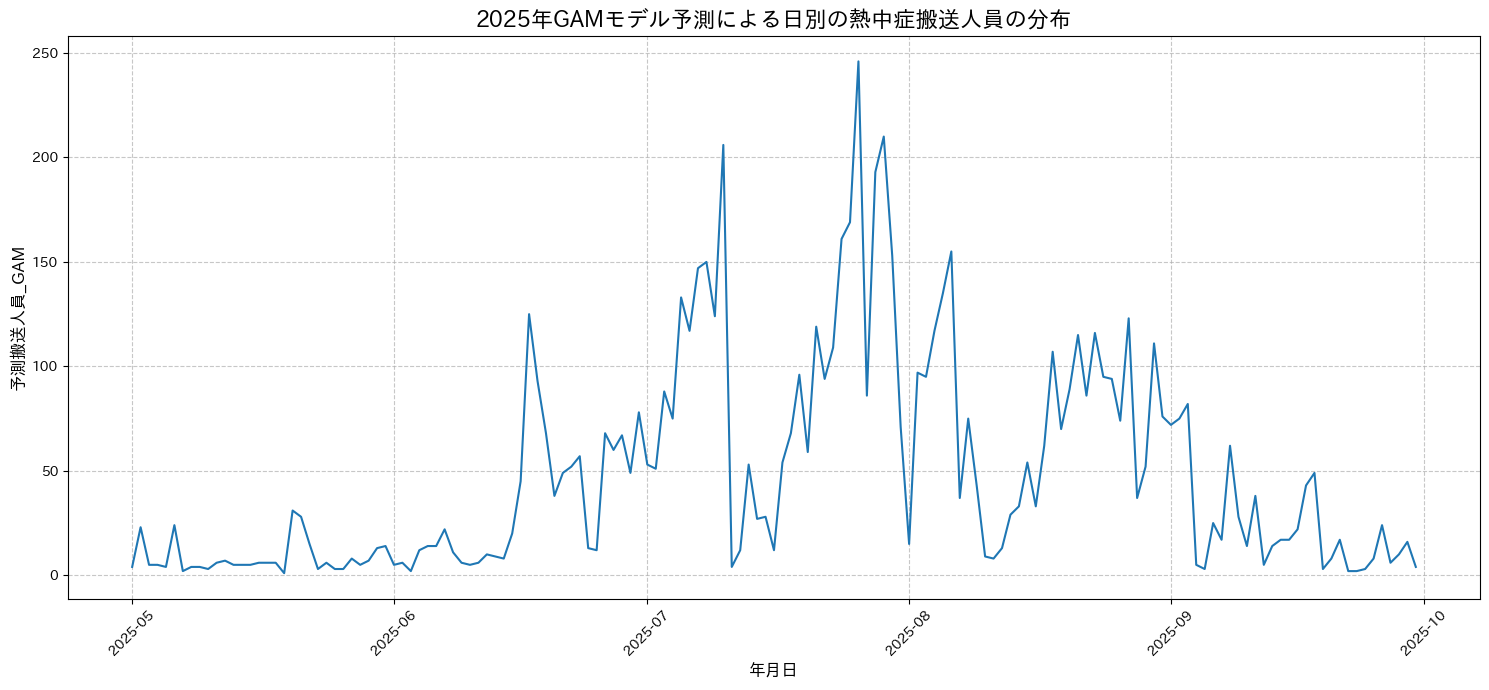

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib
import numpy as np

# df_result_gam を定義するために必要な処理をこのセルに移動
# gam_model と X_2025、df_2025 は以前のセルで定義されていることを前提とする
y_2025_pred_log_gam = gam_model.predict(X_2025)
y_2025_pred_gam = np.exp(y_2025_pred_log_gam) - 1
y_2025_pred_gam = np.maximum(y_2025_pred_gam, 0)
y_2025_pred_gam = np.round(y_2025_pred_gam).astype(int)

df_result_gam = df_2025[["年月日 東京都"]].copy()
df_result_gam["予測搬送人員_GAM"] = y_2025_pred_gam

# ここから元のプロットコード
plt.figure(figsize=(15, 7))
sns.lineplot(x='年月日 東京都', y='予測搬送人員_GAM', data=df_result_gam)
plt.title('2025年GAMモデル予測による日別の熱中症搬送人員の分布', fontsize=16)
plt.xlabel('年月日', fontsize=12)
plt.ylabel('予測搬送人員_GAM', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 7. 予測と比較

In [ ]:
ACTUAL_DATA_FILE_PATH = "/content/drive/MyDrive/heatstroke003_data_r7.xlsx" # パスが異なる場合は調整してください

df_actual_2025 = pd.read_excel(
    ACTUAL_DATA_FILE_PATH,
    sheet_name=0 # デフォルトで最初のシートをロード
)

df_actual_2025.head()

,日付,都道府県コード,搬送人員（計）,年齢区分：新生児,年齢区分：乳幼児,年齢区分：少年,年齢区分：成人,年齢区分：高齢者,年齢区分：不明,傷病程度：死亡,...,傷病程度：軽症,傷病程度：その他,発生場所：住居,発生場所：仕事場①,発生場所：仕事場②,発生場所：教育機関,発生場所：公衆(屋内),発生場所：公衆(屋外),発生場所：道路,発生場所：その他
0,2025-05-01,13,3,0,1,0,0,2,0,0,...,2,0,1,0,0,0,0,0,2,0
1,2025-05-02,13,1,0,0,0,1,0,0,0,...,1,0,1,0,0,0,0,0,0,0
2,2025-05-03,13,4,0,0,0,2,2,0,0,...,3,0,1,0,0,0,1,2,0,0
3,2025-05-04,13,3,0,0,1,1,1,0,0,...,3,0,0,0,0,0,1,2,0,0
4,2025-05-05,13,3,0,0,0,1,2,0,0,...,1,0,1,0,0,0,0,1,1,0


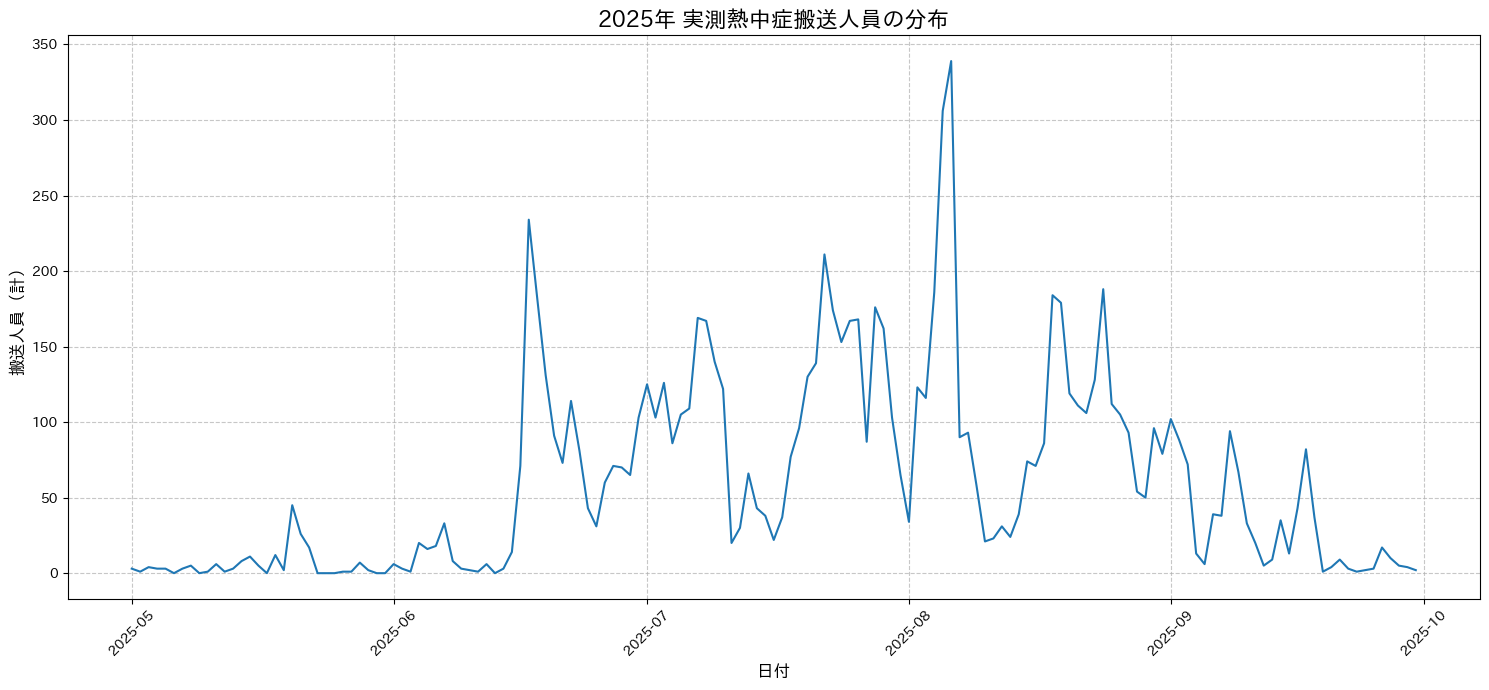

In [ ]:
# '実測データ.xlsx'ファイルから2025年の熱中症搬送人員の実測データをロードします。
# 日付列をdatetimeオブジェクトに変換します。
# 日本語フォントを使用して、2025年の熱中症搬送人員の実測数の分布を可視化するための折れ線グラフを生成します。

# df_actual_2025の「年月日 東京都」列をdatetimeオブジェクトに変換
df_actual_2025['日付'] = pd.to_datetime(df_actual_2025['日付'])

# 熱中症搬送人員の実測値をプロット
plt.figure(figsize=(15, 7))
sns.lineplot(x='日付', y='搬送人員（計）', data=df_actual_2025)
plt.title('2025年 実測熱中症搬送人員の分布', fontsize=16)
plt.xlabel('日付', fontsize=12)
plt.ylabel('搬送人員（計）', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

現在計算されている2025年のGAMモデルによる予測値と、新たにロードされた2025年の実測値を比較します。両者を同一のグラフ上にプロットし、視覚的に傾向を比較するとともに、MAEやRMSE、R-squaredなどの評価指標を計算して、モデルの実世界での性能を定量的に評価します。特に、予測が大幅に外れている期間やパターンを特定します。


In [ ]:
df_comparison = pd.merge(df_result_gam, df_actual_2025, left_on='年月日 東京都', right_on='日付', how='inner')
# 比較に必要な列を選択し、実測値を'実測搬送人員'にリネーム
df_comparison = df_comparison[['年月日 東京都', '予測搬送人員_GAM', '搬送人員（計）']]
df_comparison = df_comparison.rename(columns={'搬送人員（計）': '実測搬送人員'})
df_comparison.head()

,年月日 東京都,予測搬送人員_GAM,実測搬送人員
0,2025-05-01,4,3
1,2025-05-02,23,1
2,2025-05-03,5,4
3,2025-05-04,5,3
4,2025-05-05,4,3


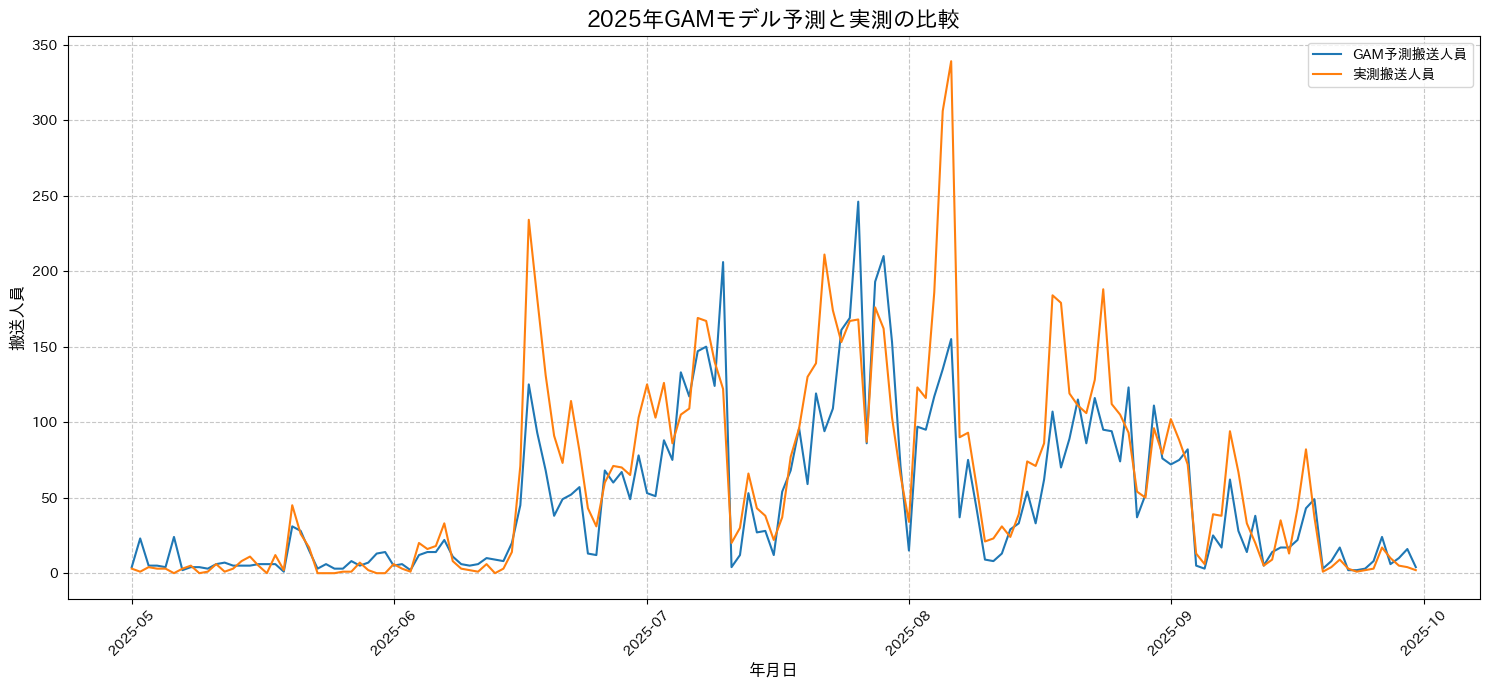

In [ ]:
plt.figure(figsize=(15, 7))
sns.lineplot(x='年月日 東京都', y='予測搬送人員_GAM', data=df_comparison, label='GAM予測搬送人員')
sns.lineplot(x='年月日 東京都', y='実測搬送人員', data=df_comparison, label='実測搬送人員')
plt.title('2025年GAMモデル予測と実測の比較', fontsize=16)
plt.xlabel('年月日', fontsize=12)
plt.ylabel('搬送人員', fontsize=12)
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
y_true = df_comparison['実測搬送人員']
y_pred = df_comparison['予測搬送人員_GAM']

mae = mean_absolute_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print(f"GAMモデル 2025年予測の評価:\n")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R-squared: {r2:.4f}")

GAMモデル 2025年予測の評価:

MAE: 21.3464
RMSE: 36.6929
R-squared: 0.6828


In [ ]:
print(gam_model.summary())

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     62.7399
Link Function:                     IdentityLink Log Likelihood:                                  -355.5174
Number of Samples:                          367 AIC:                                              838.5144
                                                AICc:                                             865.8188
                                                GCV:                                                0.6908
                                                Scale:                                              0.6944
                                                Pseudo R-Squared:                                   0.7781
Feature Function                  Lam

/tmp/ipykernel_3982/1640218013.py:1: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(gam_model.summary())


In [ ]:
df_2025["熱中症搬送人員（予測値LOG)）"] = y_2025_pred_log_gam
df_2025["熱中症搬送人員（予測値真数)"] = y_2025_pred_gam

# df_2025とdf_comparisonを結合
df_2025 = pd.merge(
    df_2025,
    df_comparison[['年月日 東京都', '実測搬送人員']],
    on='年月日 東京都',
    how='left'
)

# 結合結果の実測搬送人員をdf_2025の熱中症搬送人員（実測）列に代入
df_2025["熱中症搬送人員（実測）"] = df_2025["実測搬送人員"]

# 不要になった実測搬送人員列をdf_2025から削除
df_2025 = df_2025.drop(columns=['実測搬送人員'])

# 残差列を計算
df_2025["残差"] = df_2025["熱中症搬送人員（実測）"] - df_2025["熱中症搬送人員（予測値真数)"]

# df_2025の表示用コピーを作成し、不要な列を削除
df_2025_display = df_2025.copy()
columns_to_drop = ['day_of_week', 'day_of_week_sin', 'day_of_week_cos', 'month', 'month_sin', 'month_cos']
df_2025_display = df_2025_display.drop(columns=columns_to_drop, errors='ignore')

# 編集されたDataFrameの先頭を表示
print(df_2025_display.head())

     年月日 東京都  平均気温(℃)  最高気温(℃)  最低気温(℃)  日照時間(時間)  平均蒸気圧(hPa)  平均湿度(％)  \
0 2025-05-01     18.2     23.8     12.9      10.7        14.5       71   
1 2025-05-02     16.2     18.7     14.0       0.0        16.7       90   
2 2025-05-03     18.2     24.6     13.6      12.2        12.3       61   
3 2025-05-04     18.5     25.9     13.7       8.1        15.4       73   
4 2025-05-05     17.7     23.9     11.6       9.9        11.7       58   

   最小相対湿度(％)  熱中症搬送人員（予測値LOG)）  熱中症搬送人員（予測値真数)  熱中症搬送人員（実測）  残差  
0         44          1.612038               4            3  -1  
1         73          3.163613              23            1 -22  
2         27          1.789652               5            4  -1  
3         52          1.717411               5            3  -2  
4         37          1.609833               4            3  -1  


In [ ]:
from openpyxl import load_workbook

# 保存する前にdf_2025のコピーを作成し、不要な列を削除
df_2025_to_save = df_2025.copy()

# Excelファイルから削除する列
columns_to_drop_excel = [
    'day_of_week',
    'day_of_week_sin',
    'day_of_week_cos',
    'month',
    'month_sin',
    'month_cos'
]

# 保存用コピーから列を削除
df_2025_to_save = df_2025_to_save.drop(columns=columns_to_drop_excel, errors='ignore')

# 編集したDataFrameをExcelファイルに保存
with pd.ExcelWriter(FILE_PATH, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    df_2025_to_save.to_excel(writer, sheet_name='分析用気象_25_評価用', index=False)

print(f"更新されたdf_2025が '{FILE_PATH}' の '分析用気象_25_評価用' シートに保存されました。不要な列は削除されています。")

更新されたdf_2025が '/content/drive/MyDrive/最終ワーク_データ手順付き.xlsx' の '分析用気象_25_評価用' シートに保存されました。不要な列は削除されています。


# 8.熱中症危険日の特徴や予測と予防策につながる知見

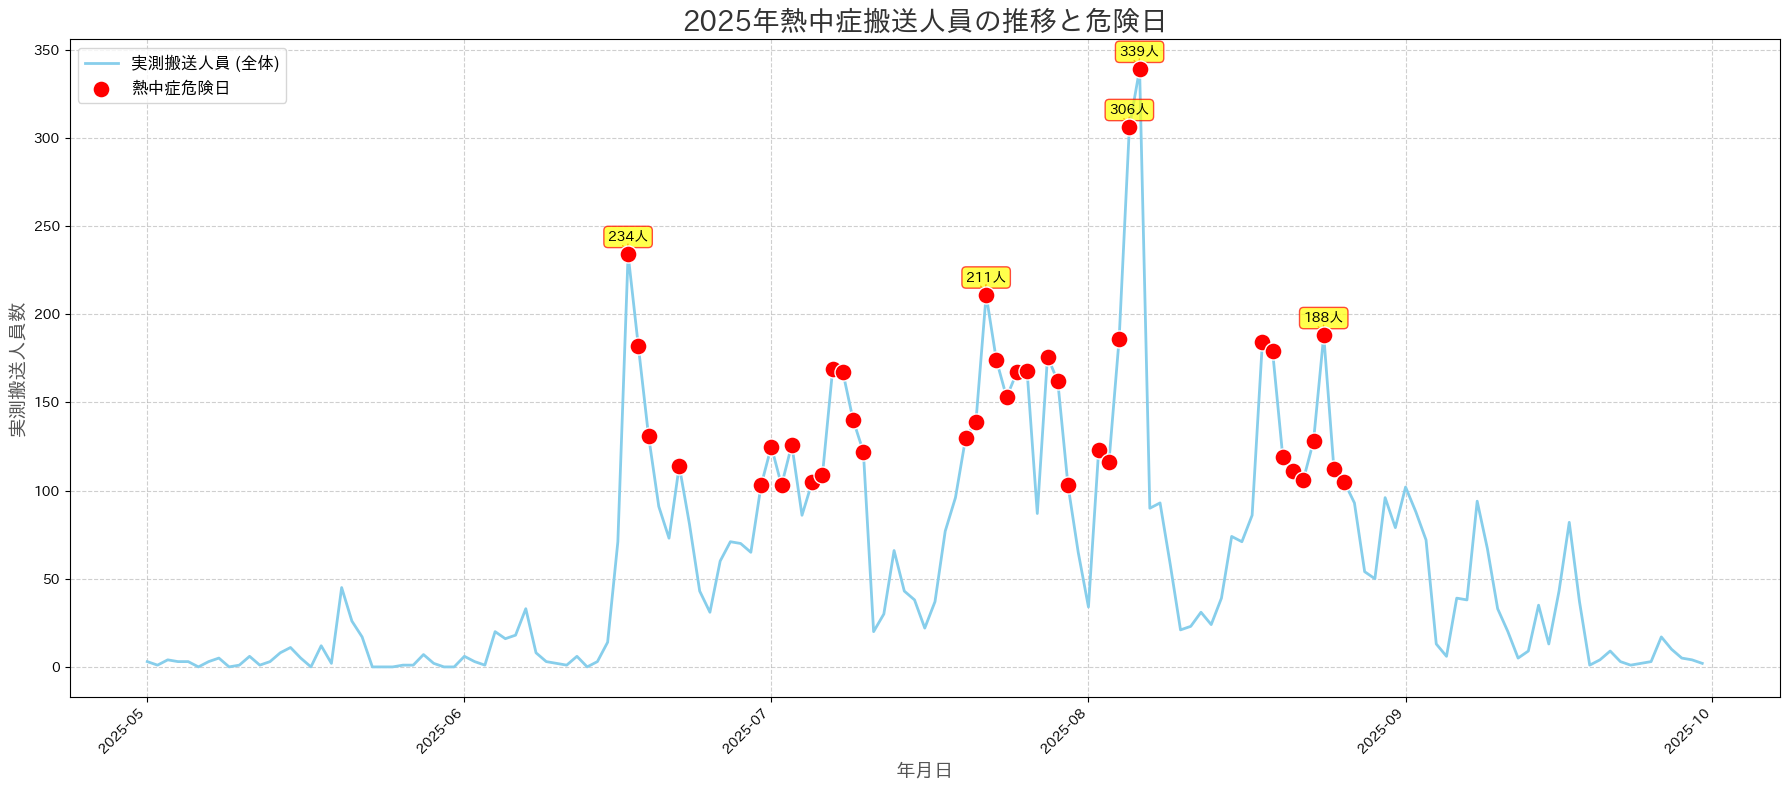


--- 熱中症危険日の特徴と予防策 ---

**「熱中症危険日」の定義:** 実測搬送人員数が全期間の75パーセンタイル (102人) を超える日です。

**危険日の気象特性 (平均):**
- 最高気温: `35.1°C`
- 平均湿度: `73.2%`
- 最小相対湿度: `52.1%`
- 平均蒸気圧: `30.3hPa`

**熱中症危険期間 (月と週の分析):**

- 6月 第3週: 3日間
- 6月 第4週: 1日間
- 6月 第5週: 1日間
- 7月 第1週: 6日間
- 7月 第2週: 3日間
- 7月 第3週: 2日間
- 7月 第4週: 6日間
- 7月 第5週: 2日間
- 8月 第1週: 5日間
- 8月 第3週: 4日間
- 8月 第4週: 5日間

**考察:**
グラフと気象データから、熱中症危険日には、**非常に高い最高気温**に加えて、**高めの湿度**が共通して観察されます。これは、体感温度が上昇し、汗が蒸発しにくくなることで体温調節機能が低下し、熱中症のリスクが著しく高まることを示しています。

**効果的な予防策:**
1.  **こまめな水分・塩分補給:** のどが渇いていなくても、カフェインを含まない飲み物やスポーツドリンクを定期的に摂取しましょう。大量に汗をかく場合は、スポーツドリンクや塩飴で塩分も補給することが重要です。
2.  **涼しい場所での活動と休憩:** 炎天下での長時間活動は避け、エアコンが効いた室内や日陰でこまめに休憩を取りましょう。無理な運動や作業は控えるべきです。
3.  **適切な服装:** 吸湿性や速乾性に優れた、風通しの良い涼しい服装を選びましょう。外出時は帽子や日傘で直射日光を避ける工夫も効果的です。
4.  **体調管理の徹底:** 睡眠を十分にとり、バランスの取れた食事を心がけ、体調が悪いと感じたらすぐに活動を中断し、医療機関を受診しましょう。
5.  **周囲への配慮と声かけ:** 高齢者、小さなお子様、持病のある方など、熱中症になりやすい方々には特に注意を払い、定期的に水分補給や休憩を促し、体調の変化に気を配りましょう。
6.  **熱中症の発生が増加する週においては、救急対応要員および救急車両の増強を実施し、救護体制の即応体制を高める

これらの対策を講じることで、熱中症の

In [ ]:
# --- 1. 熱中症危険日の定義 ---
# 実測搬送人員の75パーセンタイルを危険日の閾値とする
threshold = df_comparison['実測搬送人員'].quantile(0.75)

# 危険日を識別するフラグ列を追加
df_comparison['熱中症危険日'] = df_comparison['実測搬送人員'] > threshold

# --- 2. 危険日の気象特性を分析するためにデータを結合 ---
# df_2025から分析に必要な気象特徴量を選択
weather_features_for_analysis = [
    '年月日 東京都',
    '最高気温(℃)',
    '平均湿度(％)',
    '最小相対湿度(％)',
    '平均蒸気圧(hPa)'
]
df_weather_subset = df_2025[weather_features_for_analysis].copy()

# df_comparisonに気象データを結合
df_risk_analysis = pd.merge(df_comparison, df_weather_subset, on='年月日 東京都', how='left')

# SettingWithCopyWarningを避けるために明示的にコピーを作成
risk_days_data = df_risk_analysis[df_risk_analysis['熱中症危険日']].copy()

# --- 3. 視覚的に魅力的なグラフの生成 ---
plt.figure(figsize=(18, 8))

# 実測搬送人員を線グラフでプロット
sns.lineplot(x='年月日 東京都', y='実測搬送人員', data=df_risk_analysis, label='実測搬送人員 (全体)', color='skyblue', linewidth=2)

# 熱中症危険日を強調表示
if not risk_days_data.empty:
    sns.scatterplot(x='年月日 東京都', y='実測搬送人員', data=risk_days_data, color='red', s=150, marker='o', label='熱中症危険日', zorder=5)

    # 最も搬送人員が多い上位5日の危険日に注釈を追加
    for idx, row in risk_days_data.nlargest(5, '実測搬送人員').iterrows():
        plt.annotate(f"{row['実測搬送人員']:.0f}人",
                     (row['年月日 東京都'], row['実測搬送人員']),
                     textcoords="offset points", xytext=(0,10), ha='center',
                     bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="red", lw=1, alpha=0.7),
                     arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color='red'))

plt.title('2025年熱中症搬送人員の推移と危険日', fontsize=20, weight='bold', color='#333333')
plt.xlabel('年月日', fontsize=14, color='#555555')
plt.ylabel('実測搬送人員数', fontsize=14, color='#555555')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# --- 4. 熱中症危険日の特徴と予防策に関するコメント ---
print("""
--- 熱中症危険日の特徴と予防策 ---
""")

if not risk_days_data.empty:
    print(f"**「熱中症危険日」の定義:** 実測搬送人員数が全期間の75パーセンタイル ({threshold:.0f}人) を超える日です。")

    avg_max_temp_risk = risk_days_data['最高気温(℃)'].mean()
    avg_humidity_risk = risk_days_data['平均湿度(％)'].mean()
    avg_min_rel_humidity_risk = risk_days_data['最小相対湿度(％)'].mean()
    avg_vapor_pressure_risk = risk_days_data['平均蒸気圧(hPa)'].mean()

    # 月別および週別における熱中症の危険度評価
    risk_days_data['month'] = risk_days_data['年月日 東京都'].dt.month
    risk_days_data['week_of_month'] = risk_days_data['年月日 東京都'].dt.day.apply(lambda x: (x - 1) // 7 + 1)

    dangerous_periods = risk_days_data.groupby(['month', 'week_of_month']).size().reset_index(name='count')
    dangerous_periods = dangerous_periods.sort_values(by=['month', 'week_of_month'])

    print("""
**危険日の気象特性 (平均):**
- 最高気温: `{avg_max_temp_risk:.1f}°C`
- 平均湿度: `{avg_humidity_risk:.1f}%`
- 最小相対湿度: `{avg_min_rel_humidity_risk:.1f}%`
- 平均蒸気圧: `{avg_vapor_pressure_risk:.1f}hPa`

**熱中症危険期間 (月と週の分析):**
""".format(
        avg_max_temp_risk=avg_max_temp_risk,
        avg_humidity_risk=avg_humidity_risk,
        avg_min_rel_humidity_risk=avg_min_rel_humidity_risk,
        avg_vapor_pressure_risk=avg_vapor_pressure_risk
    ))

    if not dangerous_periods.empty:
        for index, row in dangerous_periods.iterrows():
            print(f"- {row['month']}月 第{row['week_of_month']}週: {row['count']}日間")
    else:
        print("- 分析できる危険期間はありませんでした。")

    print("""
**考察:**
グラフと気象データから、熱中症危険日には、**非常に高い最高気温**に加えて、**高めの湿度**が共通して観察されます。これは、体感温度が上昇し、汗が蒸発しにくくなることで体温調節機能が低下し、熱中症のリスクが著しく高まることを示しています。

**効果的な予防策:**
1.  **こまめな水分・塩分補給:** のどが渇いていなくても、カフェインを含まない飲み物やスポーツドリンクを定期的に摂取しましょう。大量に汗をかく場合は、スポーツドリンクや塩飴で塩分も補給することが重要です。
2.  **涼しい場所での活動と休憩:** 炎天下での長時間活動は避け、エアコンが効いた室内や日陰でこまめに休憩を取りましょう。無理な運動や作業は控えるべきです。
3.  **適切な服装:** 吸湿性や速乾性に優れた、風通しの良い涼しい服装を選びましょう。外出時は帽子や日傘で直射日光を避ける工夫も効果的です。
4.  **体調管理の徹底:** 睡眠を十分にとり、バランスの取れた食事を心がけ、体調が悪いと感じたらすぐに活動を中断し、医療機関を受診しましょう。
5.  **周囲への配慮と声かけ:** 高齢者、小さなお子様、持病のある方など、熱中症になりやすい方々には特に注意を払い、定期的に水分補給や休憩を促し、体調の変化に気を配りましょう。
6.  **熱中症の発生が増加する週においては、救急対応要員および救急車両の増強を実施し、救護体制の即応体制を高める

これらの対策を講じることで、熱中症のリスクを大幅に軽減できます。
""")
else:
    print("熱中症危険日として設定された基準を超える日がありませんでした。データを確認してください。")

## 9. 新しい条件での熱中症搬送人員予測

以下のセルで、特定の日付と気象条件を入力して、熱中症搬送人員数を予測できます。

**入力フィールド:**
- `予測したい日付` (例: `'2025-08-15'`)
- `最低気温` (℃)
- `最高気温` (℃)
- `平均湿度` (%)
- `最小相対湿度` (%)
- `平均蒸気圧` (hPa)

値を変更してセルを実行し、予測結果を確認してください。

In [ ]:
!pip install ipywidgets
from IPython.display import display, HTML

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 39.9 MB/s eta 0:00:00


In [ ]:
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
from IPython.display import display
import pandas as pd
import numpy as np

def predict_heatstroke_patients(prediction_date_str, min_temp_input, max_temp_input, avg_humidity_input, min_rel_humidity_input, avg_vapor_pressure_input):
    """
    予測したい日付と気象条件に基づいて、熱中症搬送人員数を予測する関数。
    """
    try:
        # 日付の処理
        prediction_date = pd.to_datetime(prediction_date_str)
        month = prediction_date.month
        day_of_week = prediction_date.dayofweek

        # 周期性特徴量の計算
        month_sin = np.sin(2 * np.pi * month / 12)
        month_cos = np.cos(2 * np.pi * month / 12)
        day_of_week_sin = np.sin(2 * np.pi * day_of_week / 7)
        day_of_week_cos = np.cos(2 * np.pi * day_of_week / 7)

        # 予測用データフレームの作成
        input_data = pd.DataFrame({
            '最低気温(℃)': [min_temp_input],
            '最高気温(℃)': [max_temp_input],
            '平均湿度(％)': [avg_humidity_input],
            '最小相対湿度(％)': [min_rel_humidity_input],
            '平均蒸気圧(hPa)': [avg_vapor_pressure_input],
            'month_sin': [month_sin],
            'month_cos': [month_cos],
            'day_of_week_sin': [day_of_week_sin],
            'day_of_week_cos': [day_of_week_cos]
        })

        # GAMモデルで予測
        # gam_model が前のセルで定義されていることを前提とします
        if 'gam_model' not in globals():
            print("エラー: 'gam_model' が定義されていません。モデル学習セルを実行してください。")
            return

        y_pred_log_new = gam_model.predict(input_data)
        y_pred_new = np.exp(y_pred_log_new) - 1
        y_pred_new = np.maximum(y_pred_new, 0) # 負の予測を防ぐ
        y_pred_new_rounded = np.round(y_pred_new).astype(int)

        print(f"### {prediction_date_str} の熱中症搬送人員予測:")
        print(f"予測される搬送人員数: {y_pred_new_rounded[0]} 人")

        print("\n--- 入力された条件 ---")
        print(f"日付: {prediction_date_str}")
        print(f"最低気温: {min_temp_input}°C")
        print(f"最高気温: {max_temp_input}°C")
        print(f"平均湿度: {avg_humidity_input}%")
        print(f"最小相対湿度: {min_rel_humidity_input}%")
        print(f"平均蒸気圧: {avg_vapor_pressure_input}hPa")

    except Exception as e:
        print(f"予測中にエラーが発生しました: {e}")

# インタラクティブなウィジェットの作成
prediction_date_widget = widgets.Text(value='2025-08-15', description='日付 (YYYY-MM-DD):')
min_temp_widget = widgets.FloatSlider(value=27.0, min=0.0, max=40.0, step=0.1, description='最低気温(℃):')
max_temp_widget = widgets.FloatSlider(value=35.0, min=0.0, max=45.0, step=0.1, description='最高気温(℃):')
avg_humidity_widget = widgets.IntSlider(value=75, min=0, max=100, step=1, description='平均湿度(%):')
min_rel_humidity_widget = widgets.IntSlider(value=55, min=0, max=100, step=1, description='最小相対湿度(%):')
avg_vapor_pressure_widget = widgets.FloatSlider(value=30.0, min=0.0, max=50.0, step=0.1, description='平均蒸気圧(hPa):')

# ボタンの作成
button = widgets.Button(description="予測を実行")
output = widgets.Output()

def on_button_clicked(b):
    with output:
        output.clear_output()
        predict_heatstroke_patients(
            prediction_date_widget.value,
            min_temp_widget.value,
            max_temp_widget.value,
            avg_humidity_widget.value,
            min_rel_humidity_widget.value,
            avg_vapor_pressure_widget.value
        )

button.on_click(on_button_clicked)

# すべてのウィジェットを垂直に並べて表示
display(
    widgets.VBox([
        prediction_date_widget,
        min_temp_widget,
        max_temp_widget,
        avg_humidity_widget,
        min_rel_humidity_widget,
        avg_vapor_pressure_widget,
        button,
        output
    ])
)